In [1]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor 
from sklearn.metrics import mean_absolute_error # 평균절대값오차 오차범위
from sklearn.preprocessing import StandardScaler# 정규화 클래스
from sklearn.model_selection import train_test_split
import numpy as np
from io import StringIO

In [20]:
df = pd.read_csv('data/score.csv')
df
hour = df.iloc[:,0].values
score = df.iloc[:,1].values
print(hour,score)

[ 0.5  1.2  1.8  2.4  2.6  3.2  3.9  4.4  4.5  5.   5.3  5.8  6.   6.1
  6.2  6.9  7.2  8.4  8.6 10. ] [ 10   8  14  26  22  30  42  48  38  58  60  72  62  68  72  58  76  86
  90 100]


In [22]:
train_data,test_data,train_label,test_label = train_test_split(hour,score)
train_data = train_data.reshape(-1,1)
test_data = test_data.reshape(-1,1)
train_data

array([[ 2.4],
       [ 8.6],
       [ 5.3],
       [ 7.2],
       [ 3.9],
       [ 4.5],
       [ 1.8],
       [10. ],
       [ 6.9],
       [ 5. ],
       [ 6.2],
       [ 1.2],
       [ 3.2],
       [ 6. ],
       [ 6.1]])

In [34]:
point = np.arange(1,12)
point

array([ 1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

기대점수: [107.58911425]


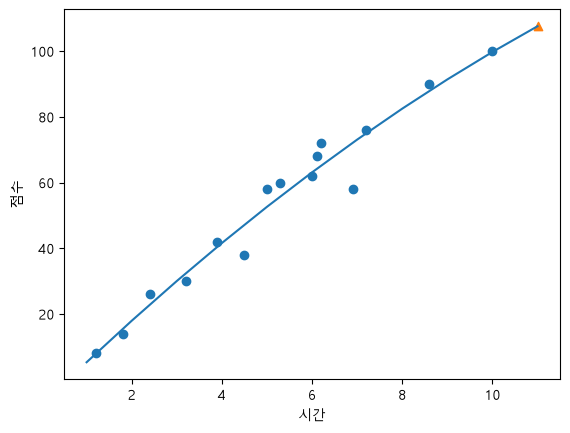

In [41]:
# 다항회귀
train_poly = np.column_stack((train_data**2,train_data))
test_poly = np.column_stack((test_data**2,test_data))

# 학습
lr = LinearRegression()
lr.fit(train_poly,train_label)

# 예측
predict = lr.predict(test_poly)
predict
# 정확도
score = lr.score(train_poly,train_label)
score2 = lr.score(test_poly,test_label)
score,score2
# 선점도 그래프
t = input('공부시간:')
t = float(t)
s = lr.predict([[t**2,t]])
print('기대점수:',s)
plt.scatter(train_data,train_label)
plt.scatter(t,s,marker='^')
plt.plot(point,lr.coef_[0]*point**2+lr.coef_[1]*point+lr.intercept_)
plt.xlabel('시간')
plt.ylabel('점수')
plt.show()